# Projeto Aplicado — Sprint 1 · Base LLVE (R05)
**Segmentação de Clientes por Valor (RFM e Clusterização) para Otimização de Marketing e Retenção em E-commerce de Moda**

| R05 | Extrair, pseudonimizar e limpar a base da LLVE |
|---|---|
| Fonte | Exportação de **pedidos** da Nuvemshop (abr/2023 – nov/2026), uma linha por item |
| Critério de aceite | Base LLVE tratada, com os pedidos válidos e **sem dados pessoais** |

> **LGPD:** este notebook lê o arquivo bruto da pasta `DADOS LLVE` (privada, fora do GitHub) e grava apenas a versão pseudonimizada em `PROCESSADOS`. Nenhuma célula exibe nome, e-mail, CPF, telefone, endereço ou dados de cartão. **Não salve este notebook no GitHub.**

### 5.1 Ambiente e parâmetros

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

from pathlib import Path
import hashlib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

BASE_DIR    = Path('/content/drive/MyDrive/PROJETO APLICADO CD/PROJETO APLICADO')
LLVE_DIR    = BASE_DIR / 'DADOS LLVE'                 # dados brutos — acesso restrito
ARQ_PEDIDOS = LLVE_DIR / 'base_pedido_23.csv'
OUTPUT_DIR  = BASE_DIR / 'PROCESSADOS'
FIG_DIR     = BASE_DIR / 'FIGURAS'
SEED = 42
PERCENTIL_CORTE = 0.999                              # mesma regra D4 da Olist, calculada na base da LLVE

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
print('Arquivo encontrado:', ARQ_PEDIDOS.exists())

Mounted at /content/drive
Arquivo encontrado: True


### 5.2 Chave secreta da pseudonimização
O identificador do cliente é um **hash SHA-256 do e-mail combinado com a chave secreta** `LLVE_SALT` (Colab Secrets). Sem a chave, não é possível voltar ao e-mail; com ela, só o autor consegue reverter o código na Sprint 3 para montar os públicos.

In [2]:
SALT = userdata.get('LLVE_SALT')
assert SALT and len(SALT) >= 16, 'Crie o secret LLVE_SALT com pelo menos 16 caracteres'

def pseudonimizar(valor):
    """Hash SHA-256 (chave + e-mail normalizado), truncado em 16 caracteres."""
    if pd.isna(valor) or str(valor).strip() == '':
        return np.nan
    texto = SALT + str(valor).strip().lower()
    return hashlib.sha256(texto.encode('utf-8')).hexdigest()[:16]

print('Chave carregada · teste de hash:', pseudonimizar('exemplo@teste.com'))

Chave carregada · teste de hash: c4302846f715d47e


### 5.3 Leitura e inspeção da estrutura (sem exibir dados)
A exportação traz **uma linha por item**; os dados do pedido (data, status, valores, endereço) aparecem só na primeira linha de cada pedido.

In [3]:
def ler_csv(caminho):
    for enc in ('utf-8', 'utf-8-sig', 'latin-1'):
        try:
            return pd.read_csv(caminho, sep=None, engine='python', encoding=enc), enc
        except UnicodeDecodeError:
            continue
    raise ValueError('Não foi possível ler o arquivo')

bruto, encoding = ler_csv(ARQ_PEDIDOS)
print(f'{len(bruto):,} linhas (itens) × {bruto.shape[1]} colunas · encoding {encoding} · '
      f'{bruto["Número do Pedido"].nunique():,} pedidos')

estrutura = pd.DataFrame({
    'tipo': bruto.dtypes.astype(str),
    '% nulos': (bruto.isna().mean() * 100).round(1),
    'valores distintos': bruto.nunique(),
})
estrutura

3,105 linhas (itens) × 61 colunas · encoding latin-1 · 1,891 pedidos


,tipo,% nulos,valores distintos
Número do Pedido,int64,0.00,1891
E-mail,object,0.00,1353
Data,object,39.10,1891
Status do Pedido,object,39.10,1
Status do Pagamento,object,39.10,3
...,...,...,...
Data de estorno,object,99.80,5
Vencimento do pagamento,object,77.60,694
Link do pedido,object,39.10,1891
Venda original,float64,100.00,0


### 5.4 Consolidação por pedido, pseudonimização e seleção de colunas
Decisões (registradas para o relatório):
| # | Decisão | Justificativa |
|---|---|---|
| L1 | `id_cliente` = hash SHA-256 (chave secreta + e-mail) | E-mail identifica o cliente entre pedidos e é a chave dos públicos personalizados do Meta Ads |
| L2 | Uma linha por pedido: cabeçalho do pedido + quantidade de itens somada | Mesma granularidade da base Olist (R02) |
| L3 | Excluir nome, CPF/CNPJ, telefones, endereço, CEP, dados do cartão, rastreio, IDs de transação, link e anotações (texto livre) | Dados pessoais ou identificáveis desnecessários ao RFM (minimização — LGPD) |
| L4 | Manter data, status, valores, canal, pagamento, parcelas, uso de cupom, cidade e UF | Variáveis do RFM, da H4 e do playbook |

In [4]:
cabecalho = bruto[bruto['Data'].notna()]
assert cabecalho['Número do Pedido'].is_unique, 'mais de um cabeçalho por pedido'

qtd_itens = bruto.groupby('Número do Pedido')['Quantidade Comprada'].sum()

MAPA = {
    'Número do Pedido': 'pedido_id', 'Data': 'data_pedido',
    'Status do Pagamento': 'status_pagamento', 'Status do Envio': 'status_envio',
    'Subtotal': 'subtotal', 'Desconto': 'desconto', 'Valor do Frete': 'frete', 'Total': 'total',
    'Estorno': 'estorno', 'Canal': 'canal', 'Forma de Pagamento': 'forma_pagamento',
    'Meio de pagamento': 'meio_pagamento', 'Parcelas': 'parcelas', 'Forma de Entrega': 'forma_entrega',
    'Cidade': 'cidade', 'Estado': 'uf',
}
pedidos = cabecalho[list(MAPA)].rename(columns=MAPA).copy()
pedidos.insert(1, 'id_cliente', cabecalho['E-mail'].map(pseudonimizar).values)
pedidos['usou_cupom'] = cabecalho['Cupom de Desconto'].notna().values
pedidos['qtd_itens'] = pedidos['pedido_id'].map(qtd_itens)

assert pedidos['id_cliente'].notna().all(), 'há pedidos sem e-mail'

colunas_excluidas = [c for c in bruto.columns if c not in MAPA and c != 'Cupom de Desconto']
del bruto, cabecalho
print(f'{len(pedidos):,} pedidos · {pedidos["id_cliente"].nunique():,} clientes pseudonimizados · '
      f'{len(colunas_excluidas)} colunas excluídas')

1,891 pedidos · 1,326 clientes pseudonimizados · 44 colunas excluídas


### 5.5 Ajuste de tipos

In [5]:
pedidos['pedido_id'] = pedidos['pedido_id'].astype(str)
pedidos['data_pedido'] = pd.to_datetime(pedidos['data_pedido'], dayfirst=True, errors='coerce')
print('Datas não reconhecidas:', pedidos['data_pedido'].isna().sum())

for col in ['subtotal', 'desconto', 'frete', 'total', 'estorno', 'parcelas']:
    pedidos[col] = pd.to_numeric(pedidos[col], errors='coerce')
pedidos['estorno'] = pedidos['estorno'].fillna(0)
pedidos['uf'] = pedidos['uf'].str.strip().str.upper().fillna('Não informado')
pedidos.dtypes.to_frame('tipo')

Datas não reconhecidas: 0


,tipo
pedido_id,object
id_cliente,object
data_pedido,datetime64[ns]
status_pagamento,object
status_envio,object
subtotal,float64
desconto,float64
frete,float64
total,float64
estorno,float64


### 5.6 Qualidade antes do tratamento

In [6]:
def retrato(df, etapa):
    return {'etapa': etapa, 'pedidos': len(df), 'clientes': df['id_cliente'].nunique(),
            'receita_R$': df['total'].sum()}
log_llve = [retrato(pedidos, '0. Base consolidada por pedido')]

print('Distribuição dos status (todos os pedidos):')
display(pd.crosstab(pedidos['status_pagamento'], pedidos['status_envio'], margins=True, margins_name='total'))

qualidade = pd.DataFrame([
    {'verificação': 'pedidos duplicados',                           'pedidos': pedidos['pedido_id'].duplicated().sum()},
    {'verificação': 'total ≠ subtotal − desconto + frete (> R$ 1)', 'pedidos': ((pedidos['subtotal'] - pedidos['desconto'] + pedidos['frete'] - pedidos['total']).abs() > 1).sum()},
    {'verificação': 'total = R$ 0',                                 'pedidos': (pedidos['total'] <= 0).sum()},
    {'verificação': 'pagamento recusado',                           'pedidos': (pedidos['status_pagamento'] == 'Recusado').sum()},
    {'verificação': 'pagamento parcialmente estornado',             'pedidos': (pedidos['status_pagamento'] == 'Parcialmente estornado').sum()},
    {'verificação': 'UF não informada',                             'pedidos': (pedidos['uf'] == 'Não informado').sum()},
])
qualidade

Distribuição dos status (todos os pedidos):


status_envio,Entregue,Enviado,Não está embalado,total
status_pagamento,,,,
Confirmado,76,1799,1,1876
Parcialmente estornado,1,4,0,5
Recusado,0,0,10,10
total,77,1803,11,1891


,verificação,pedidos
0,pedidos duplicados,0
1,total ≠ subtotal − desconto + frete (> R$ 1),0
2,total = R$ 0,1
3,pagamento recusado,10
4,pagamento parcialmente estornado,5
5,UF não informada,145


### 5.7 Filtro de pedidos válidos e valor pago
Decisões (equivalentes ao filtro `delivered` e à D1/D2 da Olist):
| # | Decisão | Justificativa |
|---|---|---|
| L5 | Excluir pedidos com pagamento **recusado** | Venda não efetivada |
| L6 | Excluir o pedido com **100% de desconto** (total = R$ 0) | Sem valor monetário, não compõe o RFM |
| L7 | Manter os **parcialmente estornados**, com `valor_pago` = total − estorno | Venda efetivada; considera apenas o valor que ficou com a empresa |
| L8 | **Status de envio não entra no filtro** | Entre os pagamentos confirmados, praticamente todos estão enviados ou entregues |
| L9 | **Manter os pedidos manuais** (registrados a partir de vendas por WhatsApp) | São clientes reais; excluí-los distorceria a frequência |
| L10 | **Usar todo o período** (abr/2023 – nov/2026) | Maximiza o histórico de recompra; a queda de volume desde 2025 é tratada na análise |

In [7]:
recusados = pedidos['status_pagamento'] == 'Recusado'
pedidos = pedidos[~recusados].copy()
log_llve.append(retrato(pedidos, '1. Remoção dos pagamentos recusados'))

sem_valor = pedidos['total'] <= 0
pedidos = pedidos[~sem_valor].copy()
log_llve.append(retrato(pedidos, '2. Remoção do pedido com 100% de desconto'))

pedidos['valor_pago'] = pedidos['total'] - pedidos['estorno']
print(f'Recusados removidos: {recusados.sum()} · sem valor removidos: {sem_valor.sum()} · '
      f'estornos descontados: R$ {pedidos["estorno"].sum():,.2f}')
print('Pedidos por canal:'); display(pedidos['canal'].value_counts().to_frame('pedidos'))

Recusados removidos: 10 · sem valor removidos: 1 · estornos descontados: R$ 649.50
Pedidos por canal:


,pedidos
canal,
Mobile,1032
Pedidos manuais,757
Loja virtual,91


### 5.8 Valores extremos (L11 — mesma regra da D4 da Olist)
Corte no **P99,9 do valor pago por pedido**, calculado sobre a distribuição da própria LLVE. Todo cliente com pedido acima do corte sai por inteiro.

In [8]:
corte_llve = pedidos['valor_pago'].quantile(PERCENTIL_CORTE)
clientes_extremos = pedidos.loc[pedidos['valor_pago'] > corte_llve, 'id_cliente'].unique()
remover = pedidos['id_cliente'].isin(clientes_extremos)

print(f'Corte P{PERCENTIL_CORTE*100:g}: R$ {corte_llve:,.2f} · pedidos acima: {(pedidos["valor_pago"] > corte_llve).sum()} · '
      f'clientes removidos: {len(clientes_extremos)} · pedidos removidos: {remover.sum()} · '
      f'{pedidos.loc[remover, "valor_pago"].sum() / pedidos["valor_pago"].sum():.1%} da receita')

antes = pedidos['valor_pago'].copy()
pedidos = pedidos[~remover].copy()
log_llve.append(retrato(pedidos, f'3. Remoção de clientes acima do P{PERCENTIL_CORTE*100:g}'))

Corte P99.9: R$ 2,654.88 · pedidos acima: 2 · clientes removidos: 2 · pedidos removidos: 2 · 0.7% da receita


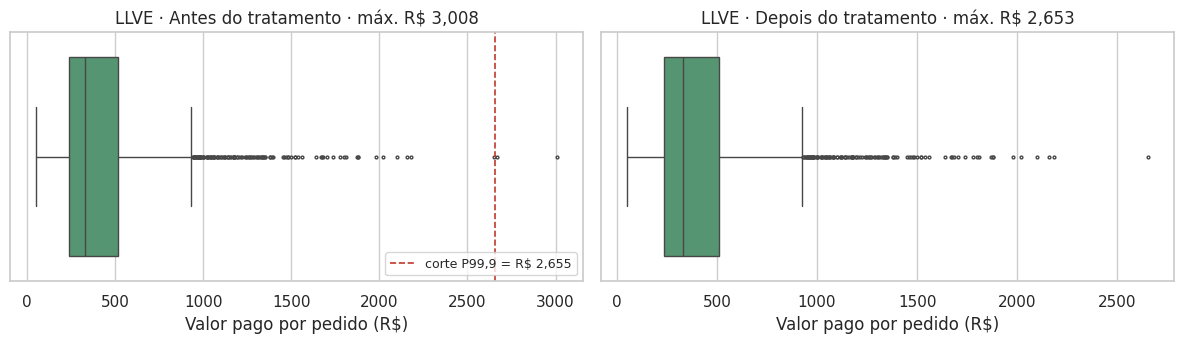

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, serie, titulo in [(axes[0], antes, 'Antes do tratamento'), (axes[1], pedidos['valor_pago'], 'Depois do tratamento')]:
    sns.boxplot(x=serie, ax=ax, color='#4C9F70', fliersize=2)
    ax.set_title(f'LLVE · {titulo} · máx. R$ {serie.max():,.0f}')
    ax.set_xlabel('Valor pago por pedido (R$)')
axes[0].axvline(corte_llve, color='#C0392B', ls='--', lw=1.2, label=f'corte P99,9 = R$ {corte_llve:,.0f}')
axes[0].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / 'R05_llve_outliers_valor_pago.png', dpi=200, bbox_inches='tight')
plt.show()

### 5.9 Qualidade depois do tratamento e validação com a Imersão Profunda
Referência do relatório (seção 1.1.1): 79,1% com uma única compra, ticket médio de R$ 413 (mediana R$ 331) e 71 clientes no perfil ideal (2+ compras e ticket médio acima de R$ 500).

In [10]:
funil_llve = pd.DataFrame(log_llve)
funil_llve['% pedidos retidos'] = funil_llve['pedidos'] / funil_llve['pedidos'].iloc[0] * 100
funil_llve['% receita retida'] = funil_llve['receita_R$'] / funil_llve['receita_R$'].iloc[0] * 100
display(funil_llve)

por_cliente = pedidos.groupby('id_cliente').agg(pedidos=('pedido_id', 'nunique'), receita=('valor_pago', 'sum'))
por_cliente['ticket_medio'] = por_cliente['receita'] / por_cliente['pedidos']
intervalos = (pedidos.sort_values('data_pedido').groupby('id_cliente')['data_pedido'].diff().dt.days.dropna())
uf_cliente = pedidos.groupby('id_cliente')['uf'].agg(lambda s: (s != 'Não informado').any())

validacao = pd.Series({
    'pedidos válidos': len(pedidos),
    'clientes compradores': len(por_cliente),
    '% com uma única compra': (por_cliente['pedidos'] == 1).mean() * 100,
    '% recompradores': (por_cliente['pedidos'] > 1).mean() * 100,
    'ticket médio por cliente (R$)': por_cliente['ticket_medio'].mean(),
    'ticket mediano por cliente (R$)': por_cliente['ticket_medio'].median(),
    'clientes no perfil ideal (2+ compras e ticket > R$ 500)': ((por_cliente['pedidos'] >= 2) & (por_cliente['ticket_medio'] > 500)).sum(),
    'intervalo mediano entre compras (dias)': intervalos.median(),
    '% de clientes com UF informada': uf_cliente.mean() * 100,
    'primeiro pedido': pedidos['data_pedido'].min().strftime('%d/%m/%Y'),
    'último pedido': pedidos['data_pedido'].max().strftime('%d/%m/%Y'),
}).to_frame('valor')
validacao

,etapa,pedidos,clientes,receita_R$,% pedidos retidos,% receita retida
0,0. Base consolidada por pedido,1891,1326,"804,303.01",100.00,100.00
1,1. Remoção dos pagamentos recusados,1881,1323,"796,156.95",99.47,98.99
2,2. Remoção do pedido com 100% de desconto,1880,1323,"796,156.95",99.42,98.99
3,3. Remoção de clientes acima do P99.9,1878,1321,"790,479.35",99.31,98.28


,valor
pedidos válidos,1878
clientes compradores,1321
% com uma única compra,79.11
% recompradores,20.89
ticket médio por cliente (R$),409.58
ticket mediano por cliente (R$),329.70
clientes no perfil ideal (2+ compras e ticket > R$ 500),70
intervalo mediano entre compras (dias),69.00
% de clientes com UF informada,95.00
primeiro pedido,12/04/2023


### 5.10 Exportação da base pseudonimizada

In [11]:
COLUNAS_PROIBIDAS = {'E-mail', 'Nome do comprador', 'Nome para a entrega', 'CPF / CNPJ', 'Telefone',
                     'Telefone para a entrega', 'Endereço', 'Número', 'Complemento', 'Bairro',
                     'Código postal', 'Dados do cartão', 'Código de rastreio do envio',
                     'Identificador da transação no meio de pagamento', 'Link do pedido',
                     'Anotações do Comprador', 'Anotações do Vendedor'}
assert not COLUNAS_PROIBIDAS.intersection(pedidos.columns), 'há colunas com dados pessoais na base de saída'

arq_llve = OUTPUT_DIR / 'llve_pedidos_tratados.parquet'
pedidos.to_parquet(arq_llve, index=False)
print(f'Salvo: {arq_llve.name} · {len(pedidos):,} pedidos · {pedidos["id_cliente"].nunique():,} clientes · '
      f'{pedidos.shape[1]} colunas · sem dados pessoais')

Salvo: llve_pedidos_tratados.parquet · 1,878 pedidos · 1,321 clientes · 20 colunas · sem dados pessoais


### 5.11 Checklist do R05
- [x] Chave secreta fora do notebook (Colab Secrets) e `id_cliente` pseudonimizado
- [x] Base consolidada em uma linha por pedido (L2), com dados pessoais excluídos e base bruta removida da memória (L3)
- [x] Pedidos recusados e com 100% de desconto removidos; estornos descontados do valor pago (L5–L7)
- [x] Pedidos manuais (WhatsApp) mantidos e período completo utilizado (L9–L10)
- [x] Clientes com pedido acima do P99,9 removidos por inteiro (L11)
- [x] Conferência com os números da Imersão Profunda
- [x] Figura `FIGURAS/R05_llve_outliers_valor_pago.png` exportada
- [x] Base salva em `PROCESSADOS/llve_pedidos_tratados.parquet`, verificada sem dados pessoais

**Nota:** a exportação de clientes (`clientes_llve_pa.csv`) deixa de ser usada na modelagem; permanece apenas como fonte dos cadastros sem compra citados na Imersão Profunda.